# Joint vs R2D2M2 vs stated scales on simulated datasets

Issue [#76](https://github.com/adkipnis/tabdgp/issues/76).

TabDGP can draw a dataset's outcome from a generalized linear mixed model (GLMM), whose priors it draws per dataset too.<br>
Independent prior scales would let the linear predictor η grow with every term, until R² nears 1 and the logit and log links saturate.<br>
TabDGP therefore draws the scales jointly, from one budget for the variance of η.<br>
The R2D2M2 prior (the R²-induced Dirichlet decomposition for multilevel models, Aguilar and Bürkner 2023) also spends a budget, but splits it over every coefficient by one Dirichlet.<br>
Real tables fix their design, so only simulated ones show how a scale draw behaves as the design grows.

This experiment checks how each draw saturates η and splits the explained variance as a grouped table gains columns, grouping factors and random effects.

- **Joint:** the sd of η drawn per dataset (from R² for a Gaussian y), split between the fixed effects and each grouping factor's random effects, whose scales are set so that each part adds its share.
- **R2D2M2:** R² ~ Beta(2, 2) and one Dirichlet over every slope and random effect, each slope's variance divided by its column's.
- **R2D2M2 on the logit and log links:** y's variance around η linearized at the intercept (Yanchenko, Bondell and Reich 2024).
- **Concentration:** a = 0.5 (`r2d2m2-0.5`) and a = 1 (`r2d2m2-1`) for R2D2M2's Dirichlet.
- **Stated:** the scales of a published model's stated priors, one model per dataset from a survey (`survey`), or every scale at 1 (`unit`), without a budget.
- **Shared:** the joint draw's families, intercept and correlations, so the draws differ by their scales alone.
- **Datasets:** TabDGP's default grouped tables, one size set per cell and the rest drawn.
- **Sizes:** d ∈ {1, 2, 4, 8, 16, 32} design columns besides the intercept, f ∈ {1, 2, 3} grouping factors and q ∈ {1, 3, 6} random effects per factor, its intercept included.
- **Floors:** at least 64 rows across d and at least 5 design columns across q, so that the widest point fits every dataset.
- **Families:** Gaussian, Bernoulli (logit link) and Poisson (log link), 1,000 datasets per cell and family.
- **Ground truth:** every measure is read off the drawn parameters, not off a fit.
- **Saturation:** the share of datasets with some |η| > 10 on the logit, or some Poisson rate above 10⁶.
- **Partition:** the marginal and conditional R² (Nakagawa, Johnson and Schielzeth 2017), the fixed share $R^2_m / R^2_c$ and each grouping factor's intraclass correlation (ICC).

`simulated.py` draws the datasets in about 100 s and writes `simulated.csv.gz`; this notebook only reads it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 72  # smaller inline images, which leaves the vector PDFs alone
records = pd.read_csv('simulated.csv.gz')
print(f'{len(records)} records, {records["index"].nunique()} datasets per cell')

180000 records, 1000 datasets per cell


## Curves

One figure per family, with a row per measure and a column per swept size.<br>
Each line is a draw's median over a cell's datasets, its band the 10-90 % range.<br>
The saturated share has no band, since it is a share of datasets.<br>
A Gaussian y has no link to saturate, so its figure has no such row.

In [2]:
MEASURES = {
    'saturated': 'saturated share',
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc_1': 'ICC of factor 1',
    'icc_2': 'ICC of factor 2',
    'icc_3': 'ICC of factor 3',
}
FIELD_LABELS = {
    'design_columns': 'd (design columns)',
    'factors': 'f (grouping factors)',
    'random_effects': 'q (random effects per factor)',
}
# three hues (joint, R2D2M2, budget-free), a dashed line for each one's second variant
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotCurves(records: pd.DataFrame, family: str) -> None:
    """One family's measures over each swept size, saved as simulated-<family>.pdf."""
    table = records[records['family'] == family]
    fields = table['field'].unique()  # the swept sizes, in the order simulated.py sweeps them
    measures = []
    for measure in MEASURES:
        if table[measure].notna().any():  # a Gaussian y never saturates
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        len(fields),
        figsize=(11, 2.1 * len(measures)),
        sharey='row',
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        banded = measure != 'saturated'  # a share of datasets has no band
        for column, field in enumerate(fields):
            ax = axes[row, column]
            swept = table[table['field'] == field]
            values = sorted(swept['value'].unique())
            cells = swept.groupby(['arm', 'value'])[measure]
            if banded:
                center = cells.median()
                low = cells.quantile(0.1)
                high = cells.quantile(0.9)
            else:
                center = cells.mean()
            for arm in table['arm'].unique():
                style = ARM_STYLES[arm]
                # a marker per cell, so a measure with one cell (a third factor's ICC) shows
                ax.plot(center[arm], **style, label=arm, linewidth=2, marker='o', markersize=4)
                if banded:
                    color = style['color']
                    ax.fill_between(low[arm].index, low[arm], high[arm], color=color, alpha=0.12)
            if field == 'design_columns':
                ax.set_xscale('log', base=2)
                ax.set_xticks(values, [str(value) for value in values])
            else:
                ax.set_xticks(values)
            ax.grid(color='#e4e3df', linewidth=0.6)
            ax.spines[['top', 'right']].set_visible(False)
            if row == len(measures) - 1:
                ax.set_xlabel(FIELD_LABELS[field])
            if column == 0:
                ax.set_ylabel(MEASURES[measure])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'simulated-{family}.pdf', metadata={'CreationDate': None})

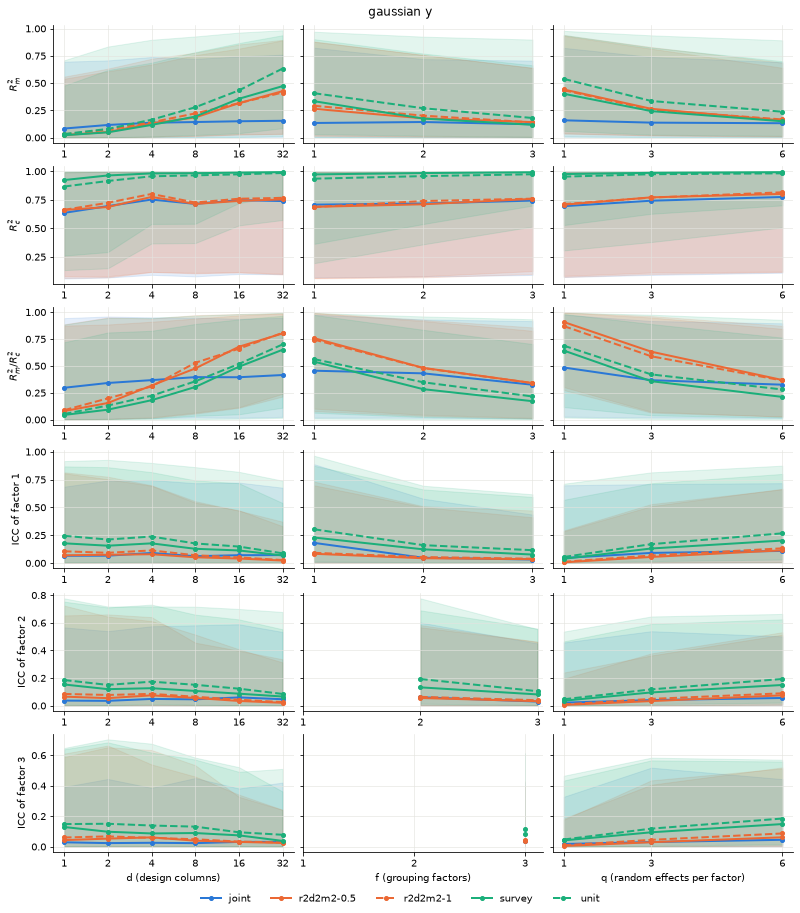

In [3]:
plotCurves(records, 'gaussian')

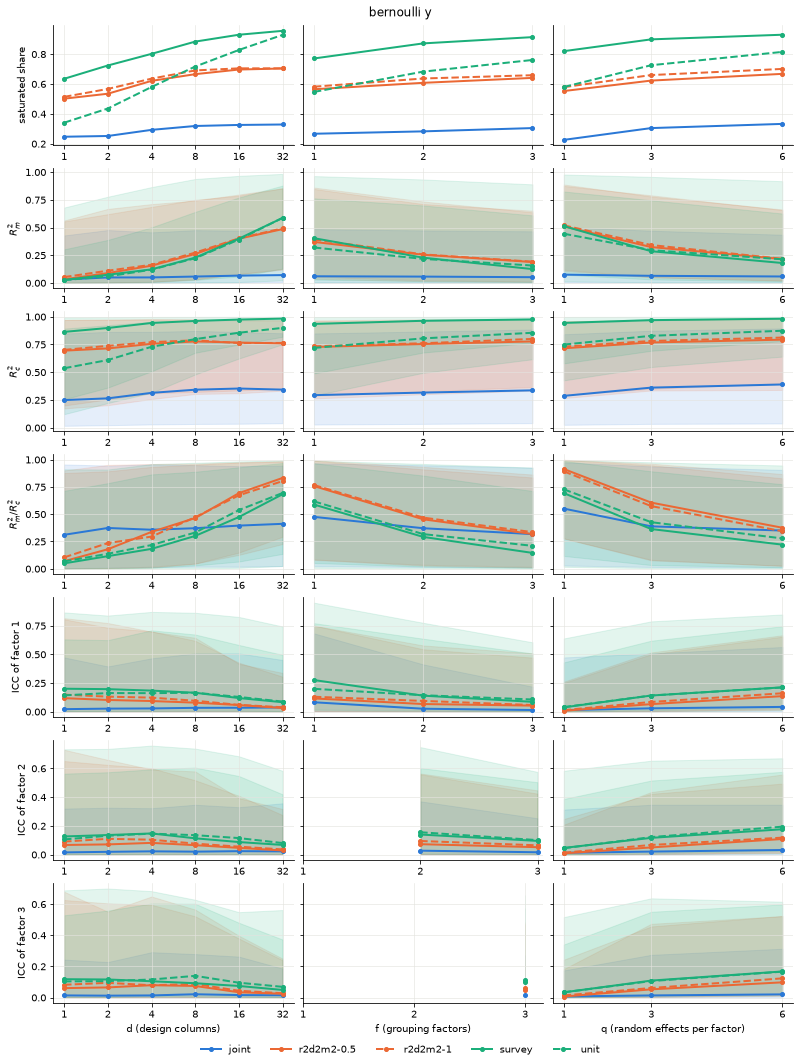

In [4]:
plotCurves(records, 'bernoulli')

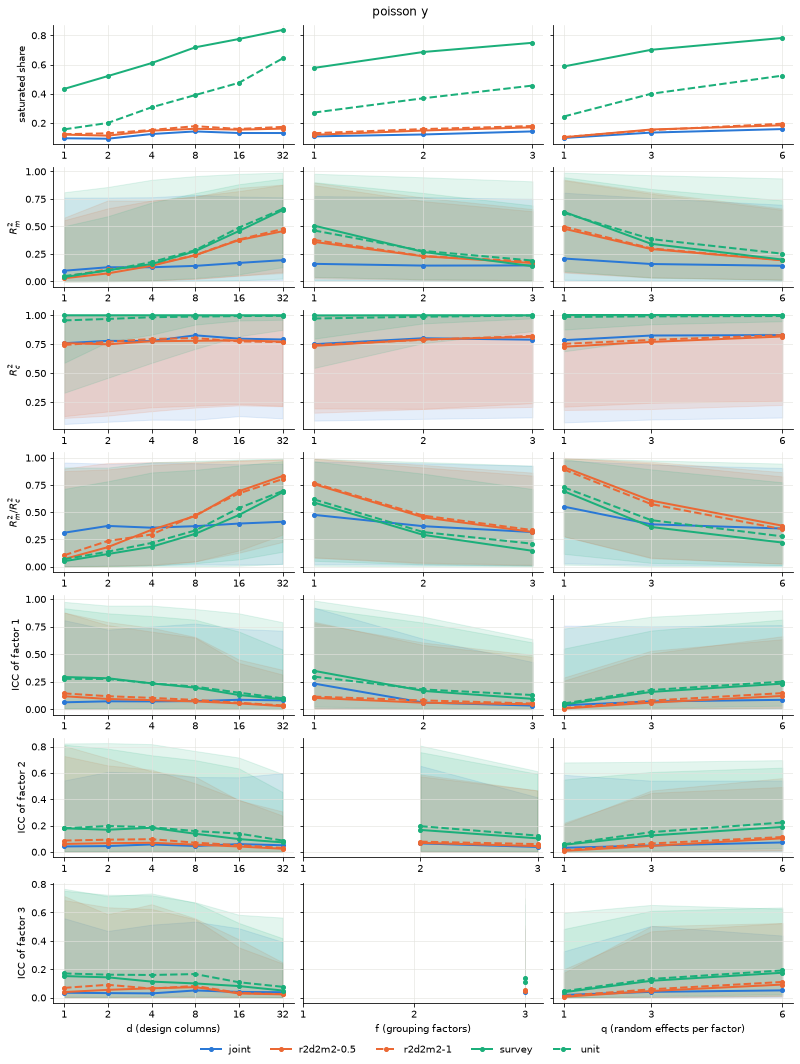

In [5]:
plotCurves(records, 'poisson')

## Finding

**Only the joint draw keeps $R^2_m$ and saturation nearly flat as d grows:**
1. Its $R^2_m$ stays below 0.2 for every family, while R2D2M2 and the stated scales climb to 0.4-0.7 at d = 32.
2. It saturates 25-33 % of the logit datasets and 9-14 % of the log-link ones, at every d.
3. R2D2M2 sets the fixed share by its count of terms, from 0.07 at d = 1 to 0.83 at d = 32 on the logit.
4. R2D2M2 saturates the logit twice as often as the joint draw, and the log link about as often.
5. Stated scales saturate both links more with every column, up to 96 % of the logit datasets at d = 32.